<div align="center">

# Teoría de Circuitos 2

## Trabajo Práctico N°11

**Estudiante: Nahir Lewartowski**

</div>

---

In [9]:
# @title
import sympy as sp
from IPython.display import display, Math
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
def mostrar_ecuacion(nombre, expr, decimales=4):
    expr_redondeada = expr.xreplace({n: round(n, decimales) for n in expr.atoms(sp.Float)})
    display(Math(f"{nombre} = " + sp.latex(expr_redondeada)))

# **1) Sistema discreto a la salida del A/D**

Se desea implementar a la salida del A/D el siguiente sistema discreto:

- Camino directo de $x(n)$ hacia un primer sumador.
- Rama de adelanto nulo: $x(n)$ pasa por $z^{-1}$, se multiplica por $-1$ y entra al primer sumador.
- La salida del primer sumador entra a un segundo sumador cuya salida es $y(n)$.
- Realimentación: $y(n)$ pasa por $z^{-1}$, se multiplica por $A$ y vuelve al segundo sumador.

**a)** Hallar la transferencia $H(z)$.

**b)** Si el coeficiente $A$ adopta valores de una tabla entre $0$ y $0{,}999$ (tendiendo a $1$), ¿qué tipo de filtro es?

**c)** Calcular el módulo y la fase para $A=0$. Graficar la respuesta en forma cualitativa.

**d)** Redibujar el diagrama en bloques si se cuenta con un solo delay unitario.

## **a) Transferencia $H(z)$**

Primera etapa (FIR):

$$w(n) = x(n) - x(n-1) \implies W(z) = X(z)\,(1 - z^{-1})$$

Segunda etapa (IIR):

$$y(n) = w(n) + A\, y(n-1) \implies Y(z) = W(z) + A\, z^{-1} Y(z)$$

$$Y(z)\,(1 - A z^{-1}) = W(z)$$

$$H(z) = \frac{Y(z)}{X(z)} = \frac{1 - z^{-1}}{1 - A z^{-1}}$$

## **b) Tipo de filtro cuando $A \to 1$**

Cero fijo en $z = 1$ (frecuencia continua, $\Omega = 0$).

Polo en $z = A$, sobre el eje real positivo.

Cuando $A$ crece hacia $0{,}999$, el polo se acerca al cero en $z=1$. El rechazo en DC se mantiene (el cero no se mueve) y la frecuencia de corte se acerca a $\Omega = 0$: el filtro sigue siendo un **pasaaltos / elimina-continua**, cada vez más selectivo cerca de la continua.

## **c) Módulo y fase para $A = 0$**

Con $A = 0$:

$$H(z) = 1 - z^{-1}$$

Sobre el círculo unitario, $z = e^{j\Omega}$:

$$H(e^{j\Omega}) = 1 - e^{-j\Omega} = e^{-j\Omega/2}\,(e^{j\Omega/2} - e^{-j\Omega/2}) = 2j\, e^{-j\Omega/2}\sin(\Omega/2)$$

$$|H(e^{j\Omega})| = 2\left|\sin\frac{\Omega}{2}\right|$$

$$\arg H(e^{j\Omega}) = \frac{\pi}{2} - \frac{\Omega}{2} \quad (0 < \Omega < 2\pi)$$

Es la versión FIR del elimina-continua (primera diferencia): anula la continua y tiene ganancia máxima en $\Omega = \pi$.

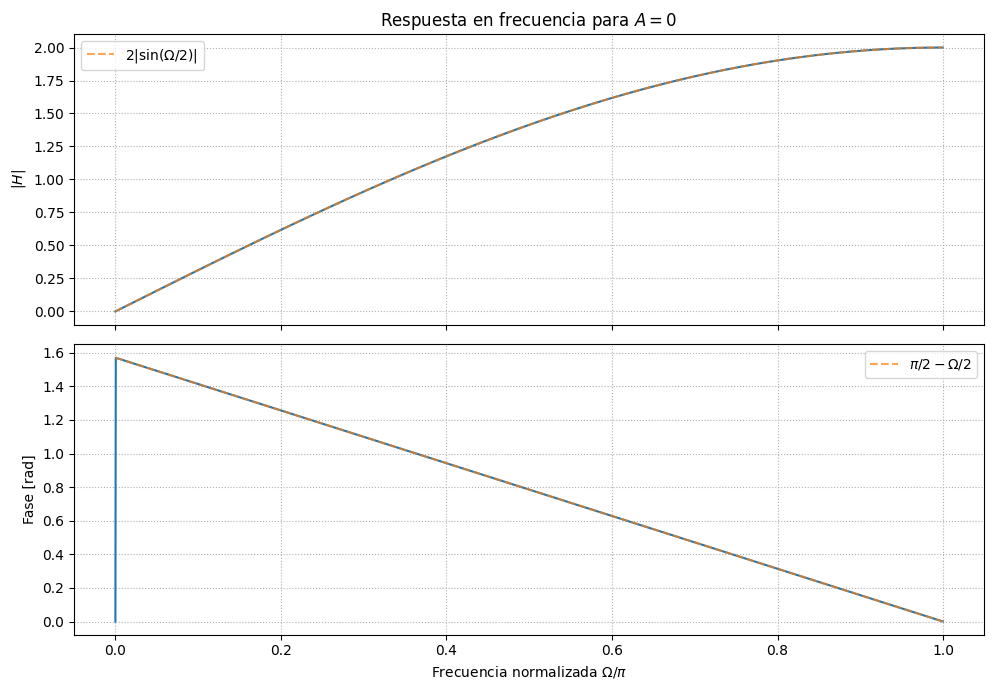

In [2]:

b = [1, -1]
a = [1]

w, h = signal.freqz(b, a, worN=2048)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(w / np.pi, np.abs(h))
axes[0].plot(w / np.pi, 2 * np.abs(np.sin(w / 2)), "--", alpha=0.7, label=r"$2|\sin(\Omega/2)|$")
axes[0].set_ylabel(r"$|H|$")
axes[0].set_title(r"Respuesta en frecuencia para $A=0$")
axes[0].grid(True, which="both", linestyle=":")
axes[0].legend()

axes[1].plot(w / np.pi, np.unwrap(np.angle(h)))
axes[1].plot(w / np.pi, np.pi / 2 - w / 2, "--", alpha=0.7, label=r"$\pi/2 - \Omega/2$")
axes[1].set_xlabel(r"Frecuencia normalizada $\Omega/\pi$")
axes[1].set_ylabel("Fase [rad]")
axes[1].grid(True, which="both", linestyle=":")
axes[1].legend()

plt.tight_layout()
plt.show()

## **d) Diagrama con un solo delay unitario**


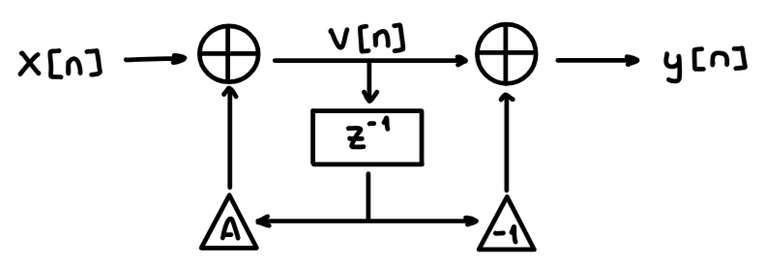

# **2) Red reactiva a partir de $|S_{21}|^2$**

Dado el parámetro

$$|S_{21}|^2 = \frac{\omega^{4}}{\omega^{4} + 4}$$

y sabiendo que es una red reactiva pura cargada en ambos puertos con un resistor de $1\,\Omega$:

**a)** Obtener la impedancia de entrada de la red cargada.

**b)** Obtener una red que satisfaga dicha impedancia de entrada.

## **a) Impedancia de entrada**

Red sin pérdidas:

$$|S_{11}|^2 = 1 - |S_{21}|^2 = \frac{4}{\omega^{4} + 4}$$

Analíticamente, con $s = j\omega$ y $\omega^{2} = -s^{2}$:

$$|S_{11}|^2 = \frac{4}{s^{4} + 4}\Big|_{s=j\omega}$$

El polinomio $s^{4} + 4 = (s^{2} + 2s + 2)(s^{2} - 2s + 2)$. Se toma el factor de Hurwitz $s^{2} + 2s + 2$ y el signo que deja $Z_{\mathrm{in}}$ real positiva:

$$S_{11}(s) = -\frac{2}{s^{2} + 2s + 2}$$

Con $R_0 = 1$:

$$Z_{\mathrm{in}}(s) = \frac{1 + S_{11}}{1 - S_{11}} = \frac{s(s + 2)}{s^{2} + 2s + 4}$$

In [3]:
s = sp.symbols("s")
S11 = -2 / (s**2 + 2*s + 2)
Zin = sp.cancel((1 + S11) / (1 - S11))
mostrar_ecuacion(r"S_{11}(s)", S11)
mostrar_ecuacion(r"Z_{\mathrm{in}}(s)", Zin)


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## **b) Síntesis de la red**

$Z_{\mathrm{in}}(0) = 0$ y $Z_{\mathrm{in}}(\infty) = 1$ indican un inductor en derivación a la entrada y una carga resistiva unitaria vista a través de un capacitor serie.

Topología:

Inductor en derivación $L = 1/2\,\mathrm{H}$
Capacitor en serie $C = 1/2\,\mathrm{F}$
Carga $R_L = 1\,\Omega$

$$Z_{\mathrm{in}} = (sL)\,\|\,\left(\frac{1}{sC} + R_L\right) = \frac{s(s+2)}{s^{2}+2s+4}$$

In [4]:
s = sp.symbols("s")
L = sp.Rational(1, 2)
C = sp.Rational(1, 2)
RL = 1

Z_branch = 1/(s*C) + RL
Zin_sint = sp.cancel(1 / (1/(s*L) + 1/Z_branch))
Zin_obj = s*(s + 2) / (s**2 + 2*s + 4)

mostrar_ecuacion(r"Z_{\mathrm{in,sint}}(s)", Zin_sint)

print(f"\n L = {L} H \n C = {C} F \n RL = {RL} Ohm")


<IPython.core.display.Math object>


 L = 1/2 H 
 C = 1/2 F 
 RL = 1 Ohm


# **3) Dipolo con impedancia dada**

Encuentre el valor de los elementos que integran el siguiente dipolo y que satisface la función impedancia propuesta:

$$Z(s) = \frac{s^{2} + 6s + 8}{s^{2} + 6s + 5}$$

$$Z(s) = R_1 + \bigl(s L_1 \| R_2\bigr) + \left(R_3 \| \frac{1}{s C_1}\right)$$

In [5]:
s = sp.symbols("s")

Z = (s**2 + 6*s + 8) / (s**2 + 6*s + 5)
mostrar_ecuacion(r"Z(s)", Z)

Z_resto = sp.cancel(Z - 1)
mostrar_ecuacion(r"Z(s) - 1", Z_resto)

Z_apart = sp.apart(Z, s)
mostrar_ecuacion(r"Z(s)\ \mathrm{(apart)}", Z_apart)

A_res, B_res = sp.Rational(3, 4), -sp.Rational(3, 4)
mostrar_ecuacion(r"Z(s)", 1 + A_res/(s + 1) + B_res/(s + 5))

C1 = 1 / A_res
R3 = 1 / (1 * C1)
R2_over_L1 = 5
R2_sq_over_L1 = -B_res
R2 = R2_sq_over_L1 / R2_over_L1
L1 = R2 / R2_over_L1
R1 = 1 - R2

print(f"R1 = {R1}")
print(f"R2 = {R2}")
print(f"R3 = {R3}")
print(f"L1 = {L1}")
print(f"C1 = {C1}")

Z_RL = (s*L1 * R2) / (s*L1 + R2)
Z_RC = (R3 * (1/(s*C1))) / (R3 + 1/(s*C1))
Z_mod = sp.cancel(R1 + Z_RL + Z_RC)
mostrar_ecuacion(r"Z_{\mathrm{circuito}}(s)", Z_mod)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

R1 = 17/20
R2 = 3/20
R3 = 3/4
L1 = 3/100
C1 = 4/3


<IPython.core.display.Math object>

### **Valores**

$$Z(s) = 1 + \frac{3/4}{s+1} - \frac{3/4}{s+5}$$

Igualando con

$$Z(s) = (R_1+R_2) - \frac{R_2^{2}/L_1}{s+R_2/L_1} + \frac{1/C_1}{s+1/(R_3 C_1)}$$

$$R_1 = \dfrac{17}{20}\,\Omega,\quad R_2 = \dfrac{3}{20}\,\Omega,\quad R_3 = \dfrac{3}{4}\,\Omega,\quad L_1 = \dfrac{3}{100}\,\mathrm{H},\quad C_1 = \dfrac{4}{3}\,\mathrm{F}$$

Verificación:

$Z(\infty) = R_1 + R_2 = 1$

$Z(0) = R_1 + R_3 = 8/5$.


# **4) Inductor real caracterizado por $S_{11}$**

Se ensaya un inductor mediante un analizador vectorial de redes para validar el modelo circuital de la hoja de datos.

La medición se realiza con resistencia de referencia unitaria ($R_o = 1$). La inductancia nominal informada por el fabricante es $L = 10$.

**a)** A partir de la expresión genérica de $S_{11}$, obtener la expresión de la **impedancia** del inductor real en función de $S_{11}$ y de $R_o$.

**b)** Luego de analizar las mediciones se llega al modelo simplificado

$$S_{11} = \frac{20s^{2} + 12s + 2}{30s^{2} + 14s + 4}$$

Empleando el resultado del punto a), obtener los valores del modelo $R_1$, $R_2$, $L$ y $C$.

Topología del modelo: $R_1$ en serie con el paralelo de $L$ y de $(R_2$ en serie con $C)$.

## **a) Impedancia a partir de $S_{11}$**

Por definición del coeficiente de reflexión referido a $R_o$:

$$S_{11} = \frac{Z - R_o}{Z + R_o} \implies Z = R_o\,\frac{1 + S_{11}}{1 - S_{11}}$$

Con $R_o = 1$:

$$Z(s) = \frac{1 + S_{11}(s)}{1 - S_{11}(s)}$$

In [6]:
s = sp.symbols("s")

S11 = (20*s**2 + 12*s + 2) / (30*s**2 + 14*s + 4)
Z = sp.cancel((1 + S11) / (1 - S11))
mostrar_ecuacion(r"Z(s)", Z)

R1 = sp.simplify(Z.subs(s, 0))
print(f"R1 = Z(0) = {R1}")

Z1 = sp.cancel(Z - R1)
mostrar_ecuacion(r"Z_1(s)", Z1)

Y1 = sp.cancel(1 / Z1)
mostrar_ecuacion(r"Y_1(s)", Y1)
k0 = sp.limit(s * Y1, s, 0)
L = 1 / k0
print(f"Residuo en el origen de Y1: {k0}  =>  L = {L} H")

Y2 = sp.cancel(Y1 - 1/(L * s))
Z2 = sp.cancel(1 / Y2)
mostrar_ecuacion(r"Z_2(s)", Z2)
R2 = sp.limit(Z2, s, sp.oo)
C = 1 / sp.limit(s * (Z2 - R2), s, sp.oo)
print(f"R2 = {R2}")
print(f"C = {C}")

print("\nValores: \n R1 =", R1, "\n R2 =", R2, "\n L =", L, "\n C =", C)


<IPython.core.display.Math object>

R1 = Z(0) = 3


<IPython.core.display.Math object>

<IPython.core.display.Math object>

Residuo en el origen de Y1: 1/10  =>  L = 10 H


<IPython.core.display.Math object>

R2 = 2
C = 1/2

Valores: 
 R1 = 3 
 R2 = 2 
 L = 10 
 C = 1/2


### **Valores del modelo (por remociones)**

1. $Z(0) = R_1 = 3\,\Omega$
2. $Z_1 = Z - 3$; $Y_1 = 1/Z_1$; residuo en el origen $\Rightarrow L = 10\,\mathrm{H}$
3. Resto invertido: $Z_2 = 2 + 2/s$ $\Rightarrow R_2 = 2\,\Omega$, $C = 1/2\,\mathrm{F}$

$$R_1 = 3\,\Omega,\quad R_2 = 2\,\Omega,\quad L = 10\,\mathrm{H},\quad C = \dfrac{1}{2}\,\mathrm{F}$$

La inductancia extraída coincide con el valor nominal $L = 10$ del fabricante.


# **5) Síntesis de transimpedancia cargada**

Sintetice la siguiente **transimpedancia** cargada a la entrada, que respete la siguiente función y condiciones de carga:

$$Z(s) = \frac{V_2}{I_g} = k\,\frac{P(s)}{Q(s)}$$

$Z(s)$ tiene ceros de transmisión en $\omega = 1/4$ y $\omega = 0$.
$Z(s)$ debe ser de **máxima planicidad** con un ripple de $3\,\mathrm{dB}$ en la banda de paso.

**A.** Realizar la síntesis gráfica para obtener la topología circuital sin valores.

**B.** Obtener los valores de los componentes para satisfacer la respuesta pedida.

**C.** Verificar la síntesis por el método que se considere más conveniente y ajustar $k$ para que tenga $-6\,\mathrm{dB}$ en el centro de la banda de paso.

### **Hipótesis adoptadas** (el enunciado no fija $P$, $Q$, el orden ni $R_g$)

- Numerador mínimo: $P(s) = s\,(s^{2} + 1/16)$ (ceros en $\omega=0$ y $\omega=1/4$).
- Denominador Butterworth de orden 3 normalizado a $3\,\mathrm{dB}$ en $\omega=1$: $Q(s) = s^{3} + 2s^{2} + 2s + 1$.
- $R_g = 1$.

$$Z(s) = k\,\frac{s\,(s^{2} + 1/16)}{s^{3} + 2s^{2} + 2s + 1}$$

## **A. Síntesis gráfica**

1. Separar $Q(s)$ en parte par $M(s)$ e impar $N(s)$ y formar $Z_{11} = N/M$.
2. Remoción **parcial** de un inductor en derivación a la entrada, elegida para forzar un cero de $Y_A$ en $\omega = 1/4$.
3. El polo de $Z_A = 1/Y_A$ en $\omega = 1/4$ se realiza con un **tanque LC en paralelo**, ubicado en la rama serie. En $\omega = 1/4$ ese tanque se abre y aparece el cero de transmisión. Un LC en serie, en cambio, se cerraría en esa frecuencia.
4. El remanente es un inductor en derivación hacia el puerto de salida (circuito abierto en $V_2$).

Topología resultante: $L_1$ en derivación, tanque paralelo $(L_2 \| C_2)$ en la rama serie, y $L_3$ en derivación.

## **B. Valores de los componentes**

In [7]:
s = sp.symbols("s")

P0 = s * (s**2 + sp.Rational(1, 16))
Q = s**3 + 2*s**2 + 2*s + 1
M = 2*s**2 + 1
N = s**3 + 2*s

Z11 = N / M
Y11 = 1 / Z11
mostrar_ecuacion(r"Z_{11}(s)", Z11)

w_z2 = -sp.Rational(1, 16)
L1_p = sp.symbols("L1_p", positive=True)
sYA_eval = sp.cancel(s * Y11).subs(s**2, w_z2)
L1_val = sp.solve(sp.Eq(sYA_eval - 1/L1_p, 0), L1_p)[0]
print(f"L1 (remoción parcial) = {L1_val} H")

YA = sp.simplify(Y11 - 1/(L1_val * s))
ZA = sp.simplify(1 / YA)

kz = sp.cancel(ZA * (s**2 + sp.Rational(1, 16)) / s).subs(s**2, w_z2)
C2_val = 1 / kz
L2_val = 1 / (C2_val * (-w_z2))
print(f"Tanque paralelo en serie: C2 = {C2_val} F, L2 = {L2_val} H")

Z_tanque = (kz * s) / (s**2 + sp.Rational(1, 16))
ZB = sp.simplify(ZA - Z_tanque)
L3_val = sp.simplify(ZB / s)
print(f"L3 = {L3_val} H")

L3a = L3_val / 2
L3b = L3_val / 2
print(f"Divisor: L3a = L3b = {L3a} H")

Z21 = sp.cancel(s**2 * L1_val * L3_val / (Z_tanque + s*(L1_val + L3_val)))
Z11_red = sp.cancel(1 / (1/(s*L1_val) + 1/(Z_tanque + s*L3_val)))
T_red = sp.cancel(Z21 / (1 + Z11_red))
T_div = sp.cancel(T_red / 2)

mostrar_ecuacion(r"V_2/I_g\ \mathrm{(red\ LC)}", T_red)
mostrar_ecuacion(r"V_2/I_g\ \mathrm{(con\ divisor)}", T_div)

<IPython.core.display.Math object>

L1 (remoción parcial) = 31/14 H
Tanque paralelo en serie: C2 = 768/961 F, L2 = 961/48 H
L3 = 31/48 H
Divisor: L3a = L3b = 31/96 H


<IPython.core.display.Math object>

<IPython.core.display.Math object>

## **C. Verificación y ajuste de $k$ a $-6\,\mathrm{dB}$**

Con $R_g = 1$ y la salida abierta, la transimpedancia de la red LC es

$$\frac{V_2}{I_g} = \frac{Z_{21}}{1 + Z_{11}} = \frac{s\,(s^{2} + 1/16)}{s^{3} + 2s^{2} + 2s + 1}$$

o sea $k = 1$. La meseta de la banda de paso (alta frecuencia) vale $|Z(j\infty)| = 1$ ($0\,\mathrm{dB}$).

Para llevar esa meseta a $-6\,\mathrm{dB}$ sin transformador ideal, se parte el inductor de salida:

$$L_3 = \frac{31}{48}\,\mathrm{H} = L_{3a} + L_{3b},\qquad L_{3a} = L_{3b} = \frac{31}{96}\,\mathrm{H}$$

$V_2$ se toma en el punto medio del divisor. Hacia el cuadripolo la impedancia sigue siendo $s L_3$, y la tensión medida es la mitad:

$$k = \frac{1}{2} \quad\Rightarrow\quad 20\log_{10}|k| = -6\,\mathrm{dB}$$


Red LC, $k=1$ (0 dB): meseta HF = -0.00 dB
Con divisor inductivo, k=1/2: meseta HF = -6.02 dB


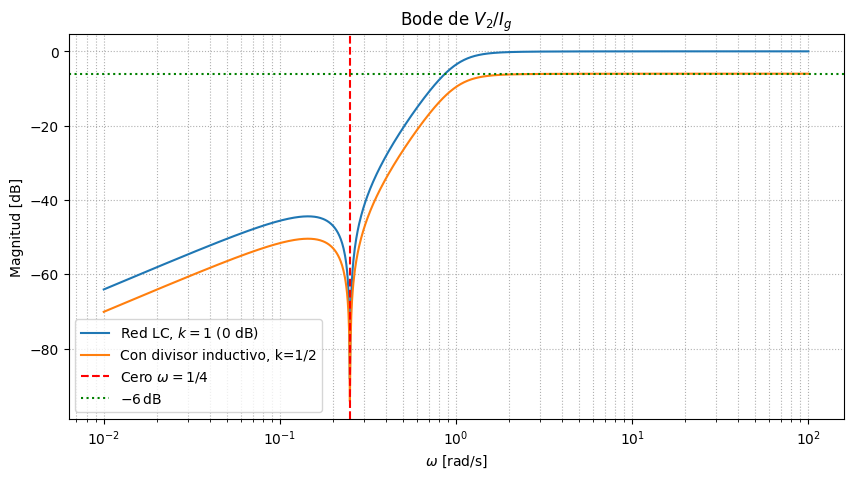

In [8]:
den = [1, 2, 2, 1]
casos = [
    (1.0, r"Red LC, $k=1$ (0 dB)"),
    (0.5, r"Con divisor inductivo, k=1/2"),
]

w = np.logspace(-2, 2, 1000)
plt.figure(figsize=(10, 5))
for k_plot, etiqueta in casos:
    num = [k_plot, 0, k_plot/16, 0]
    _w, mag, _ph = signal.bode(signal.TransferFunction(num, den), w)
    plt.semilogx(_w, mag, label=etiqueta)
    print(f"{etiqueta}: meseta HF = {mag[-1]:.2f} dB")

plt.axvline(0.25, color="red", linestyle="--", label=r"Cero $\omega=1/4$")
plt.axhline(-6, color="green", linestyle=":", label=r"$-6\,\mathrm{dB}$")
plt.title(r"Bode de $V_2/I_g$")
plt.xlabel(r"$\omega$ [rad/s]")
plt.ylabel("Magnitud [dB]")
plt.grid(True, which="both", linestyle=":")
plt.legend()
plt.show()


### **Resumen del ejercicio 5**

| Elemento | Valor |
|---|---|
| $L_1$ | $31/14\,\mathrm{H}$ |
| $L_2 \parallel C_2$ (tanque en la rama serie) | $L_2 = 961/48\,\mathrm{H}$, $C_2 = 768/961\,\mathrm{F}$ |
| $L_3 = L_{3a}+L_{3b}$ | $31/48\,\mathrm{H}$ |
| $L_{3a} = L_{3b}$ (divisor) | $31/96\,\mathrm{H}$ |
| $k$ de la red LC con $R_g = 1$ | $1$ ($0\,\mathrm{dB}$ en alta frecuencia) |
| $k$ con divisor inductivo | $1/2$ ($-6\,\mathrm{dB}$) |
